# Results walkthrough

This notebook reads the saved results in `results/tables/` and the figures in `results/figures/` (no data download or model fitting needed) and shows the numbers behind the paper. Each step that produced them is a module of the `kinetic_mech` package; the README gives the order to run them.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display

from kinetic_mech import config as C
from kinetic_mech.features import COLUMNS, families, keep_columns

pd.set_option('display.width', 160)

## 1. The dataset
Data-quality checks (a random subset of 100,000 training experiments and every test set) and the share of each mechanism in each split.

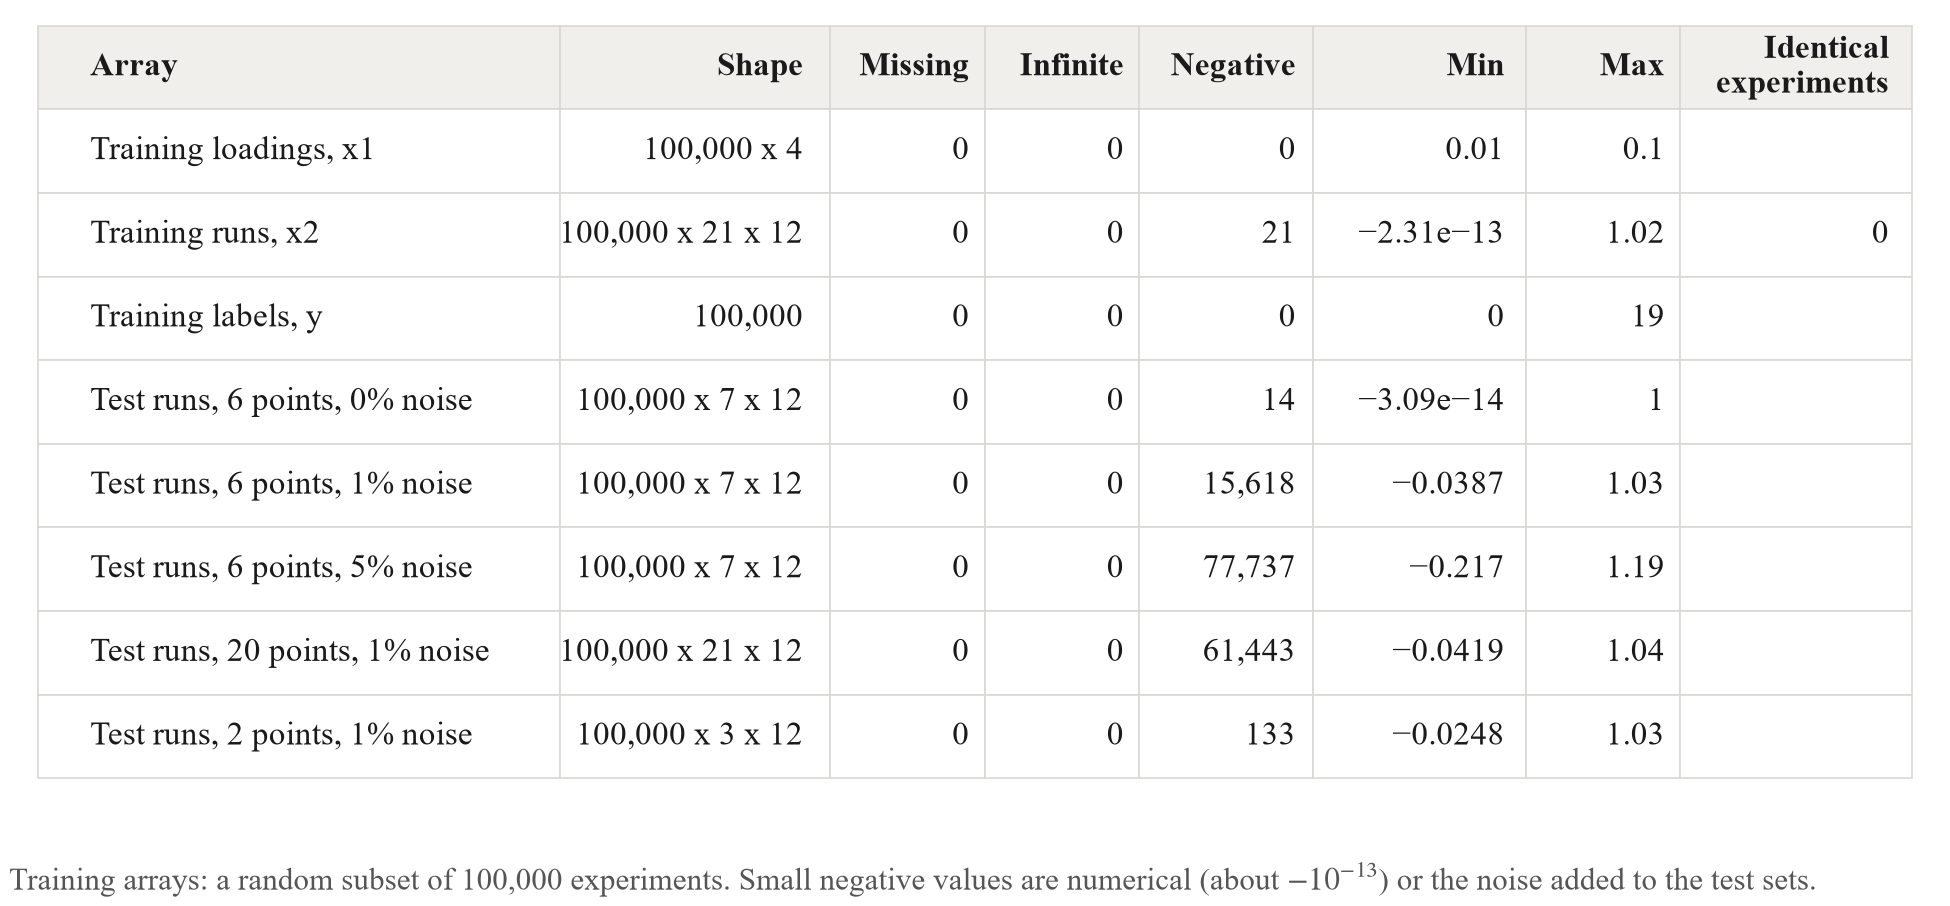

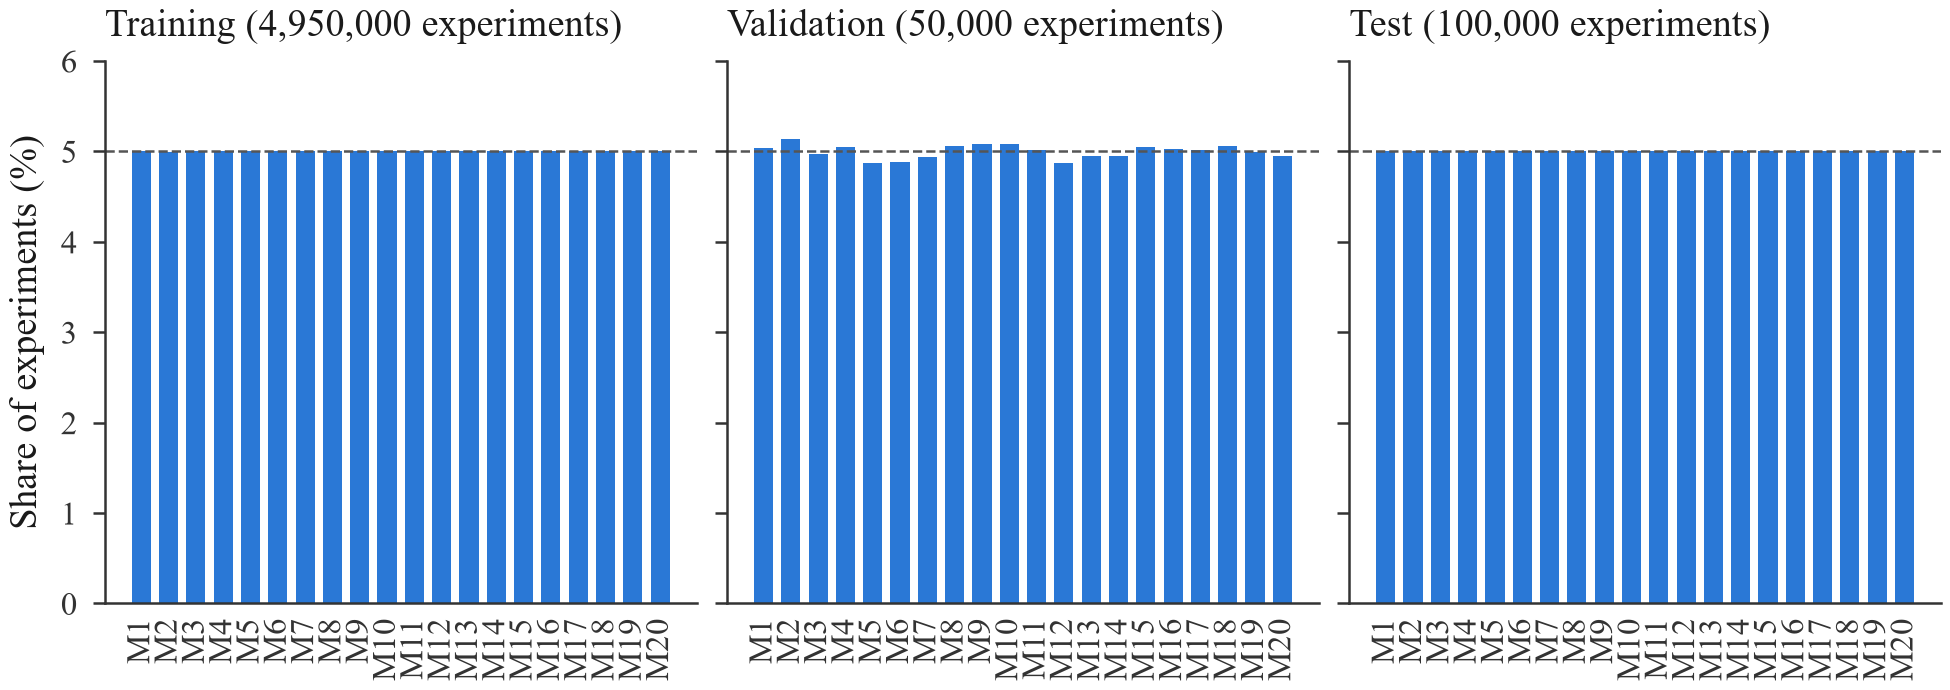

In [2]:
display(Image(C.SUPPORTING / 'eda' / 'data_quality.png', width=750))
display(Image(C.SUPPORTING / 'eda' / 'class_balance.png', width=750))

## 2. Features
136 engineered features in 12 families; the correlation filter (Pearson |r| ≥ 0.9, keep the feature with more mutual information with the mechanism) leaves 84.

In [3]:
fam = families(COLUMNS)
kept = set(keep_columns('84'))
pd.DataFrame({'features': {f: len(cs) for f, cs in fam.items()},
              'kept': {f: sum(c in kept for c in cs) for f, cs in fam.items()}}).loc[C.FAMILY_ORDER]

,features,kept
Pooled order (VTNA),12,11
Catalyst order (run pairs),6,4
Same-excess test,5,4
Selwyn test,4,3
Integrated fit (MM),9,7
Death laws,22,14
Inhibitor laws,16,7
Mass deficit,5,4
Deficit Km fit,12,10
Curve shapes,36,11


In [4]:
pairs = pd.read_csv(C.TABLES / 'eda' / 'pairs_abs_r_ge_0.9.csv')
dist = pd.read_csv(C.TABLES / 'eda' / 'distribution_84.csv')
summ = pd.read_csv(C.TABLES / 'eda' / 'feature_summary_136.csv')
print('pairs with |r| >= 0.9:', len(pairs))
print('values missing in the 136 features: %.2f%%' % summ.missing_pct.mean())
print('extreme values in the 84 features: %.2f%%' % (100 * dist.n_extreme.sum() / dist.n_values.sum()))

pairs with |r| >= 0.9: 113
values missing in the 136 features: 2.08%
extreme values in the 84 features: 3.53%


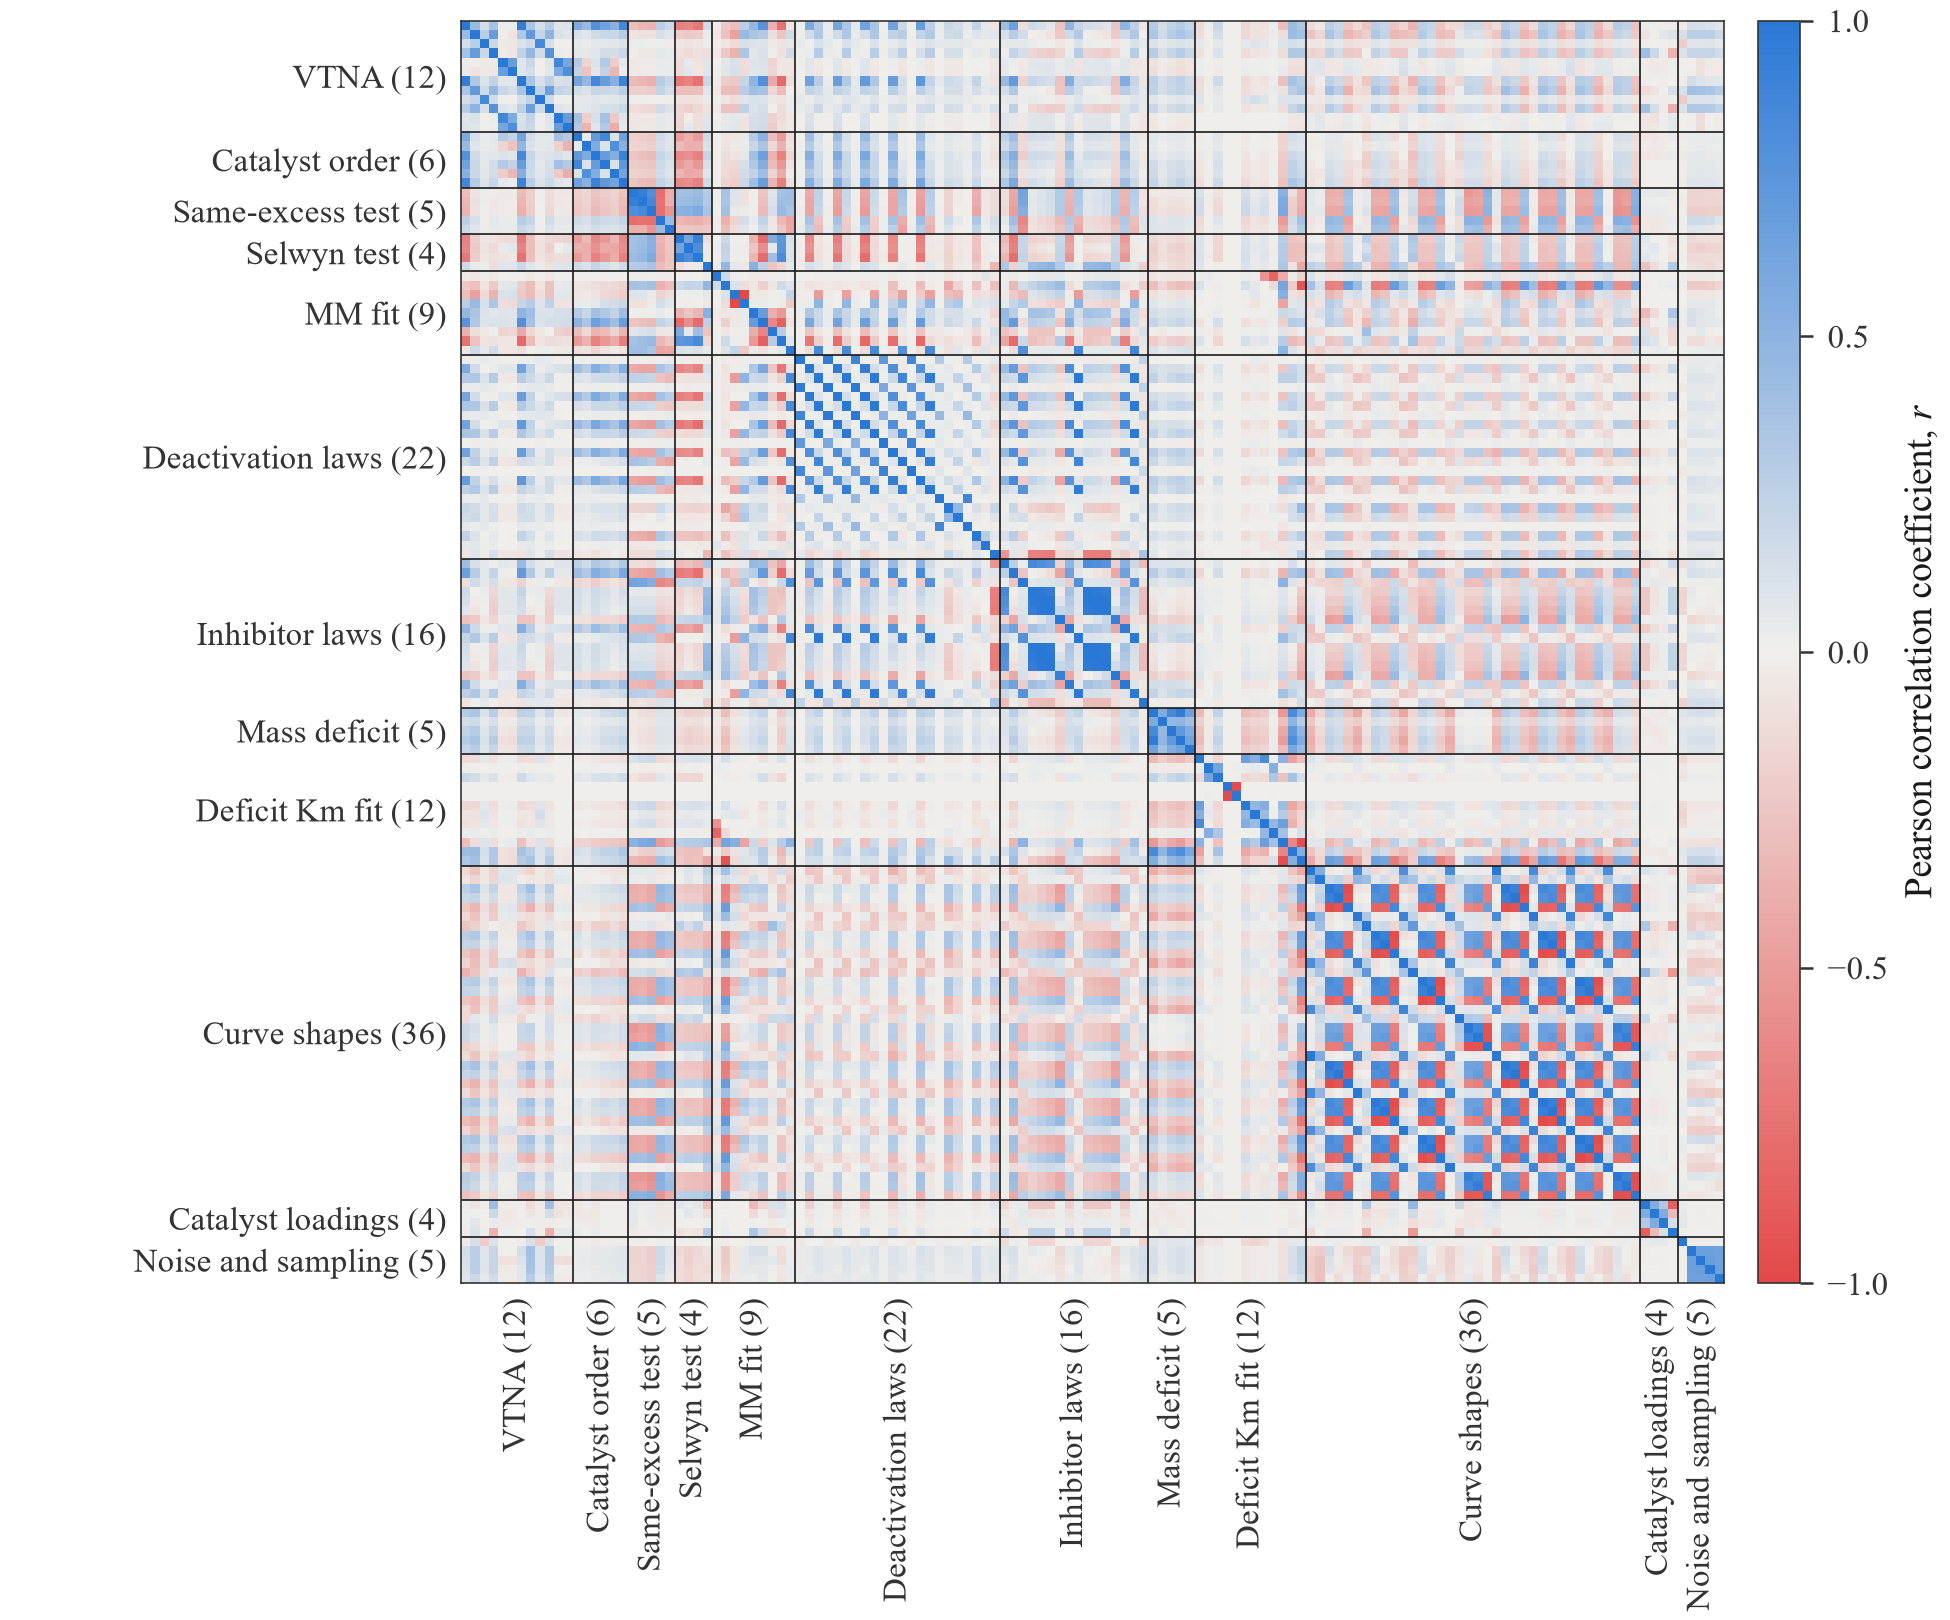

In [5]:
display(Image(C.REPORT / 'Appendix_4_pearson_correlation.png', width=700))

## 3. Model selection
Every model was fitted on the same 204,800 training rows and scored on the validation set; the tie rule picked LightGBM, which was then refitted on all 4,947,968 training rows.

In [6]:
search = pd.read_csv(C.TABLES / 'search.csv')
search.sort_values('val_accuracy', ascending=False).groupby('model').head(1)

,model,setting,params,val_accuracy,val_logloss_bits,rounds,fit_min
13,hgb,1,"{""l2_regularization"": 0.11630396231968025, ""le...",0.71126,1.423954,651.0,9.616804
29,lightgbm,1,"{""feature_fraction_bynode"": 0.8, ""learning_rat...",0.71050,1.192009,949.0,6.245132
26,xgboost,6,"{""colsample_bynode"": 0.5, ""learning_rate"": 0.0...",0.70712,1.150218,906.0,7.708919
9,random_forest,3,"{""max_features"": 0.3, ""min_samples_leaf"": 10}",0.64390,1.595275,NaN,3.787109
4,decision_tree,4,"{""max_depth"": 20, ""min_samples_leaf"": 20}",0.53478,6.674875,NaN,0.532902


In [7]:
w = json.load(open(C.TABLES / 'winner.json'))
print(w['rule'])
print('winner:', w['model'], 'setting', w['setting'], w['params'])

highest validation accuracy; within 0.3 points counts as tied; lower validation log loss wins
winner: lightgbm setting 1 {'feature_fraction_bynode': 0.8, 'learning_rate': 0.04480603542592627, 'min_child_samples': 50, 'num_leaves': 85, 'reg_lambda': 2.0442263898005057, 'subsample': 0.85}


Accuracy (%) of every model on the validation set and the five released test sets:

In [8]:
res = pd.read_csv(C.TABLES / 'results.csv')
(res.assign(accuracy=lambda d: (100 * d.accuracy).round(2))
    .pivot(index='model', columns='set', values='accuracy'))

set,test_20pts_1pct,test_2pts_1pct,test_6pts_0pct,test_6pts_1pct,test_6pts_5pct,validation
model,,,,,,
"Decision tree (204,800 rows)",65.38,46.00,75.94,60.35,31.72,53.48
Dummy (class prior),5.00,5.00,5.00,5.00,5.00,4.88
"Gradient boosting (scikit-learn) (204,800 rows)",81.90,65.06,88.18,78.04,45.91,71.13
"LightGBM (204,800 rows)",82.04,65.02,88.30,78.18,45.86,71.05
"LightGBM, final (4,947,968 rows)",85.40,70.53,90.46,81.79,49.55,75.91
"Random forest (204,800 rows)",76.31,57.90,84.63,71.72,40.34,64.39
"XGBoost (204,800 rows)",81.73,64.46,87.99,77.69,45.86,70.71


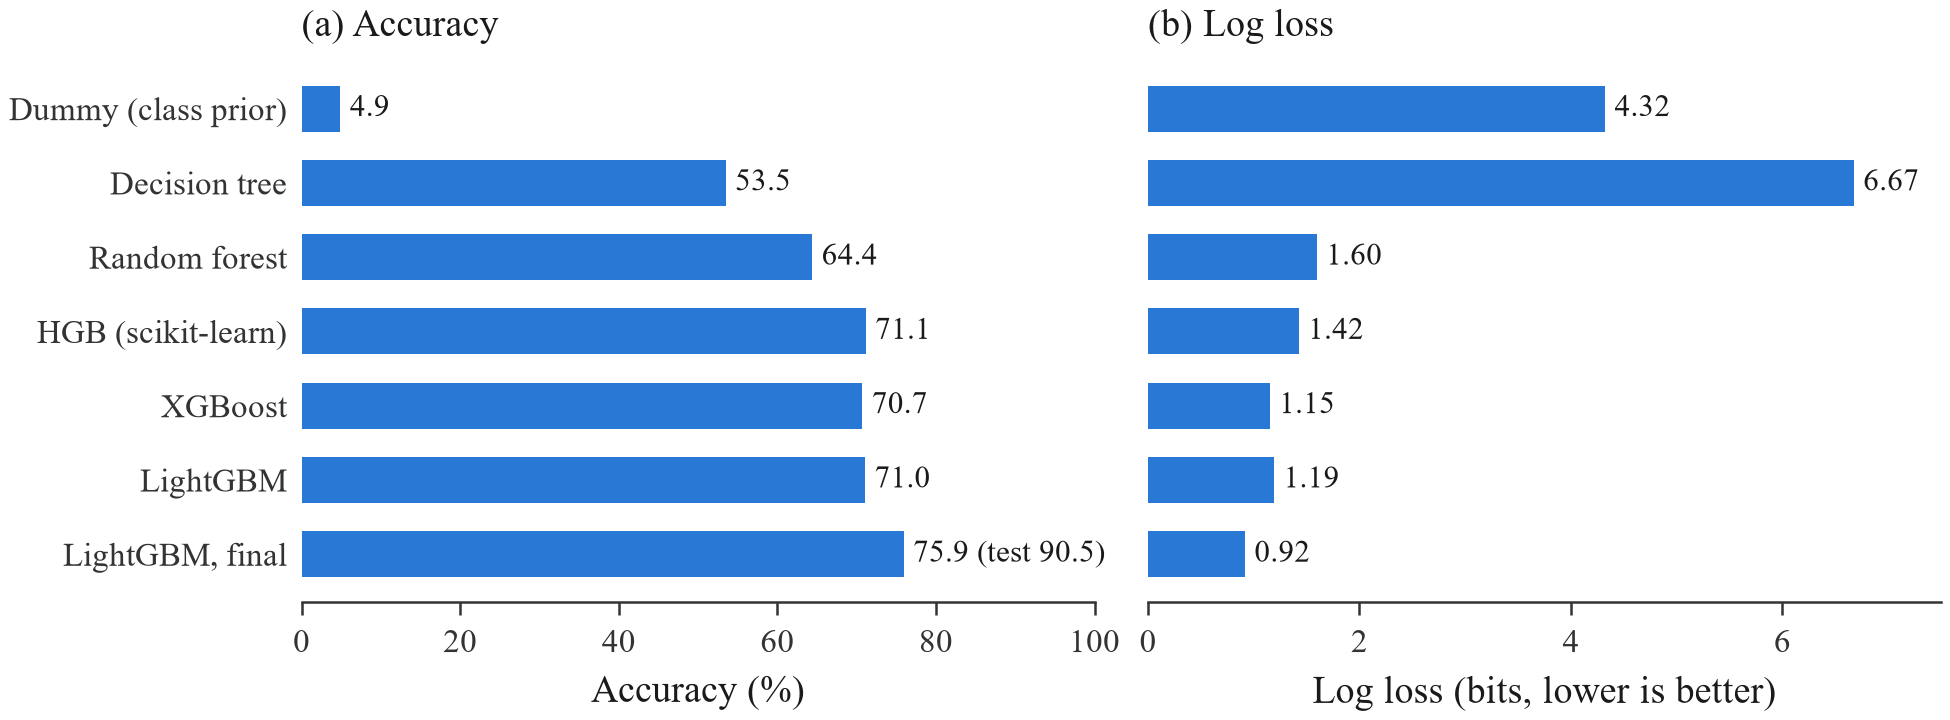

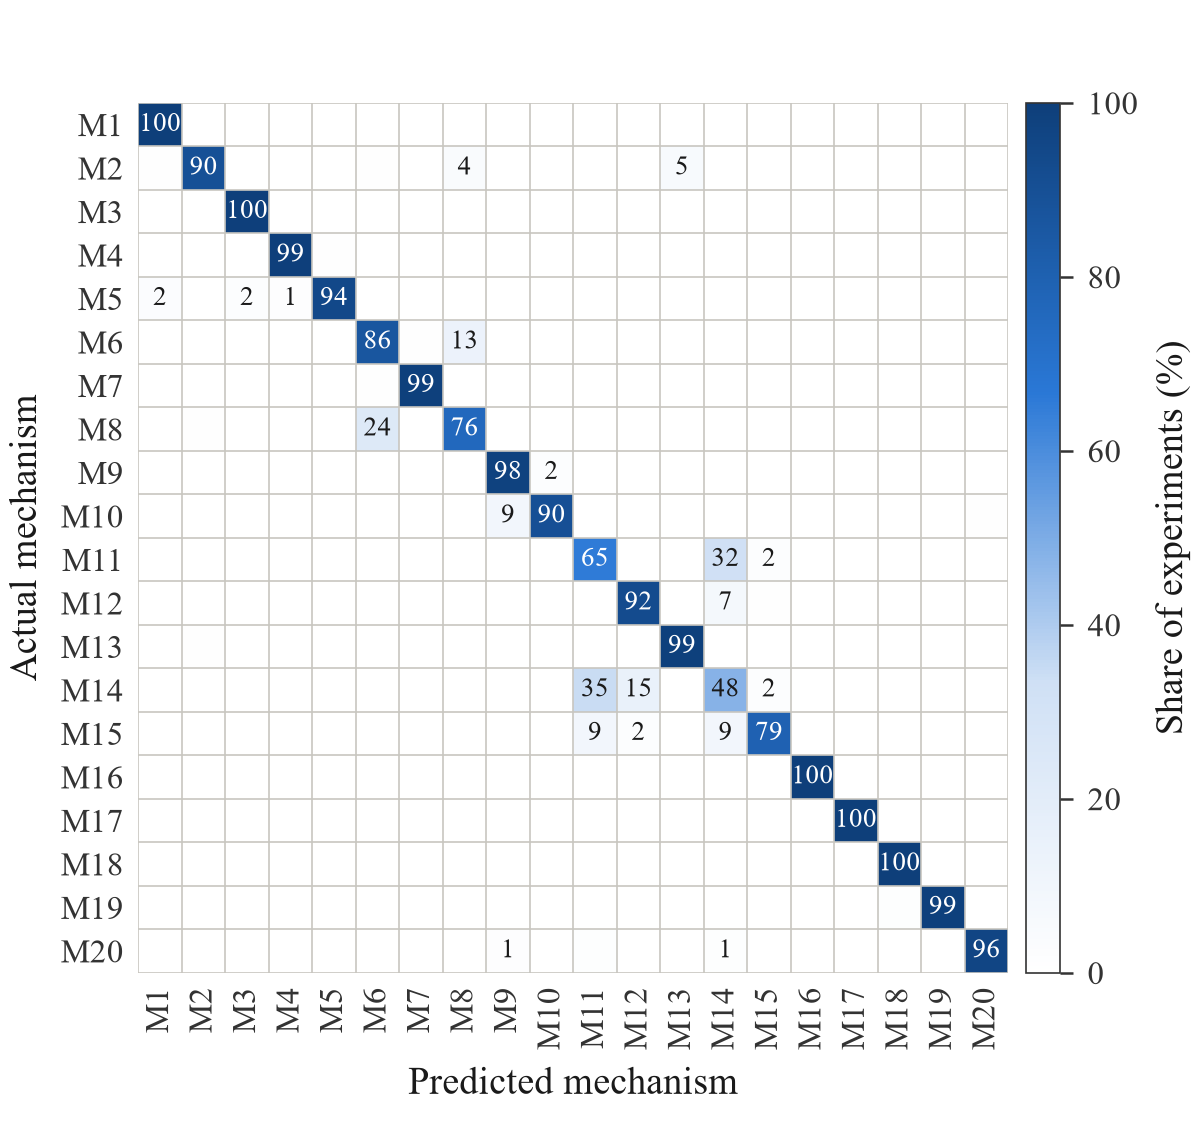

In [9]:
display(Image(C.SUPPORTING / 'figures' / 'models_validation.png', width=700))
display(Image(C.SUPPORTING / 'figures' / 'confusion_test_6pts_0pct.png', width=500))

Recall and top-2 recall of the final model on the main test set (6 points per run, no noise):

In [10]:
t2 = pd.read_csv(C.TABLES / 'top2_recall.csv')
(t2[t2.set == C.MAIN_TEST].set_index('mechanism')[['recall', 'top2_recall']] * 100).round(1).T

mechanism,M1,M2,M3,M4,M5,M6,M7,M8,M9,M10,M11,M12,M13,M14,M15,M16,M17,M18,M19,M20
recall,99.8,89.5,99.5,99.2,94.2,86.3,99.0,75.6,97.7,90.0,65.5,92.2,99.0,48.0,79.3,99.7,99.9,99.9,99.1,95.9
top2_recall,100.0,99.6,100.0,100.0,99.8,99.9,99.6,99.7,99.9,99.2,98.2,99.1,99.9,97.0,86.5,100.0,100.0,100.0,100.0,98.3


## 4. Grouped permutation importance
Each family (and block of families) was permuted together on the test set, three times; changes are in percentage points. The role describes how the recall losses spread over the mechanisms.

In [11]:
pd.read_csv(C.TABLES / 'permutation' / 'family_summary.csv').round(2)

,unit,kind,n_columns,accuracy_change_points,accuracy_change_sd_points,mechanisms_affected,largest_loss_points,largest_loss_mech,role,breadth,top_category,top_category_share
0,block Fitted laws,block,28,-54.37,0.13,20,90.51,M1,Generalist,17.90,Deactivation,0.62
1,block Mass balance,block,14,-47.04,0.21,20,79.35,M17,Generalist,17.32,Deactivation,0.70
2,Mass deficit,family,4,-24.12,0.05,15,67.06,M17,Group specialist,12.08,Deactivation,0.91
3,block Graphical tests,block,22,-20.48,0.12,18,74.20,M6,Generalist,10.07,Bicatalytic,0.38
4,Death laws,family,14,-20.27,0.05,16,60.65,M19,Generalist,11.21,Deactivation,0.75
5,Deficit Km fit,family,10,-18.16,0.16,16,49.45,M3,Generalist,12.54,Deactivation,0.43
6,Curve shapes,family,11,-16.61,0.05,17,62.91,M6,Generalist,12.01,Deactivation,0.52
7,Inhibitor laws,family,7,-7.41,0.07,8,31.09,M11,Generalist,7.31,Deactivation,0.74
8,Pooled order (VTNA),family,11,-6.59,0.05,6,59.69,M8,Intermediate,3.78,Activation,0.45
9,Integrated fit (MM),family,7,-5.95,0.04,6,61.00,M1,Intermediate,3.27,Core,0.52


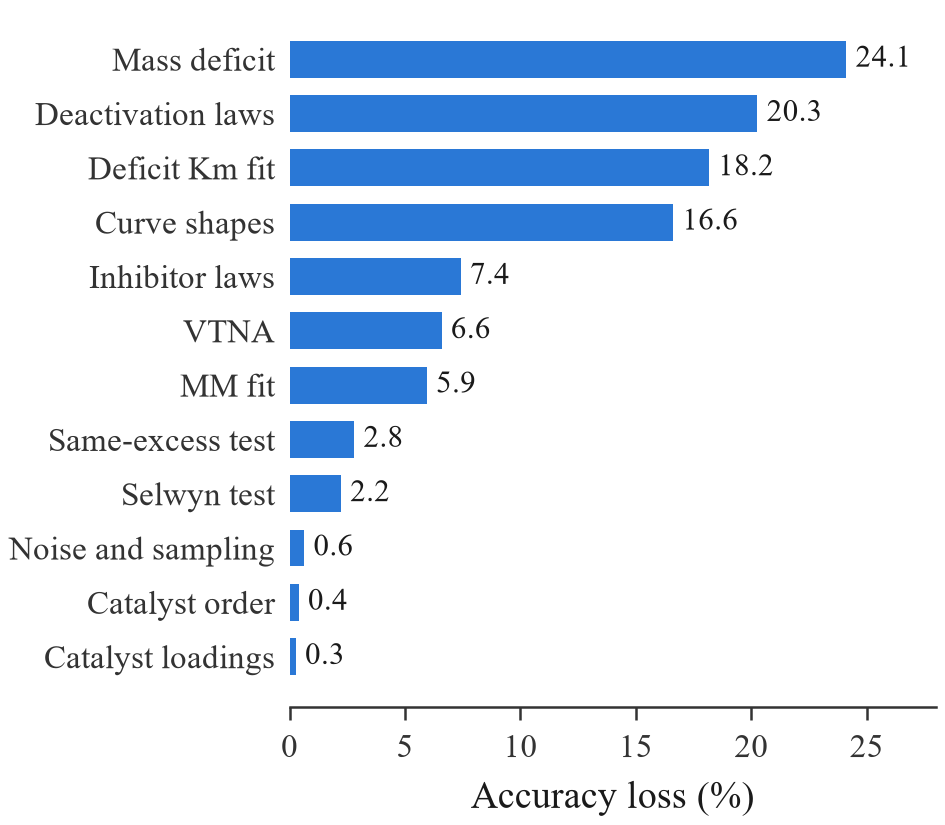

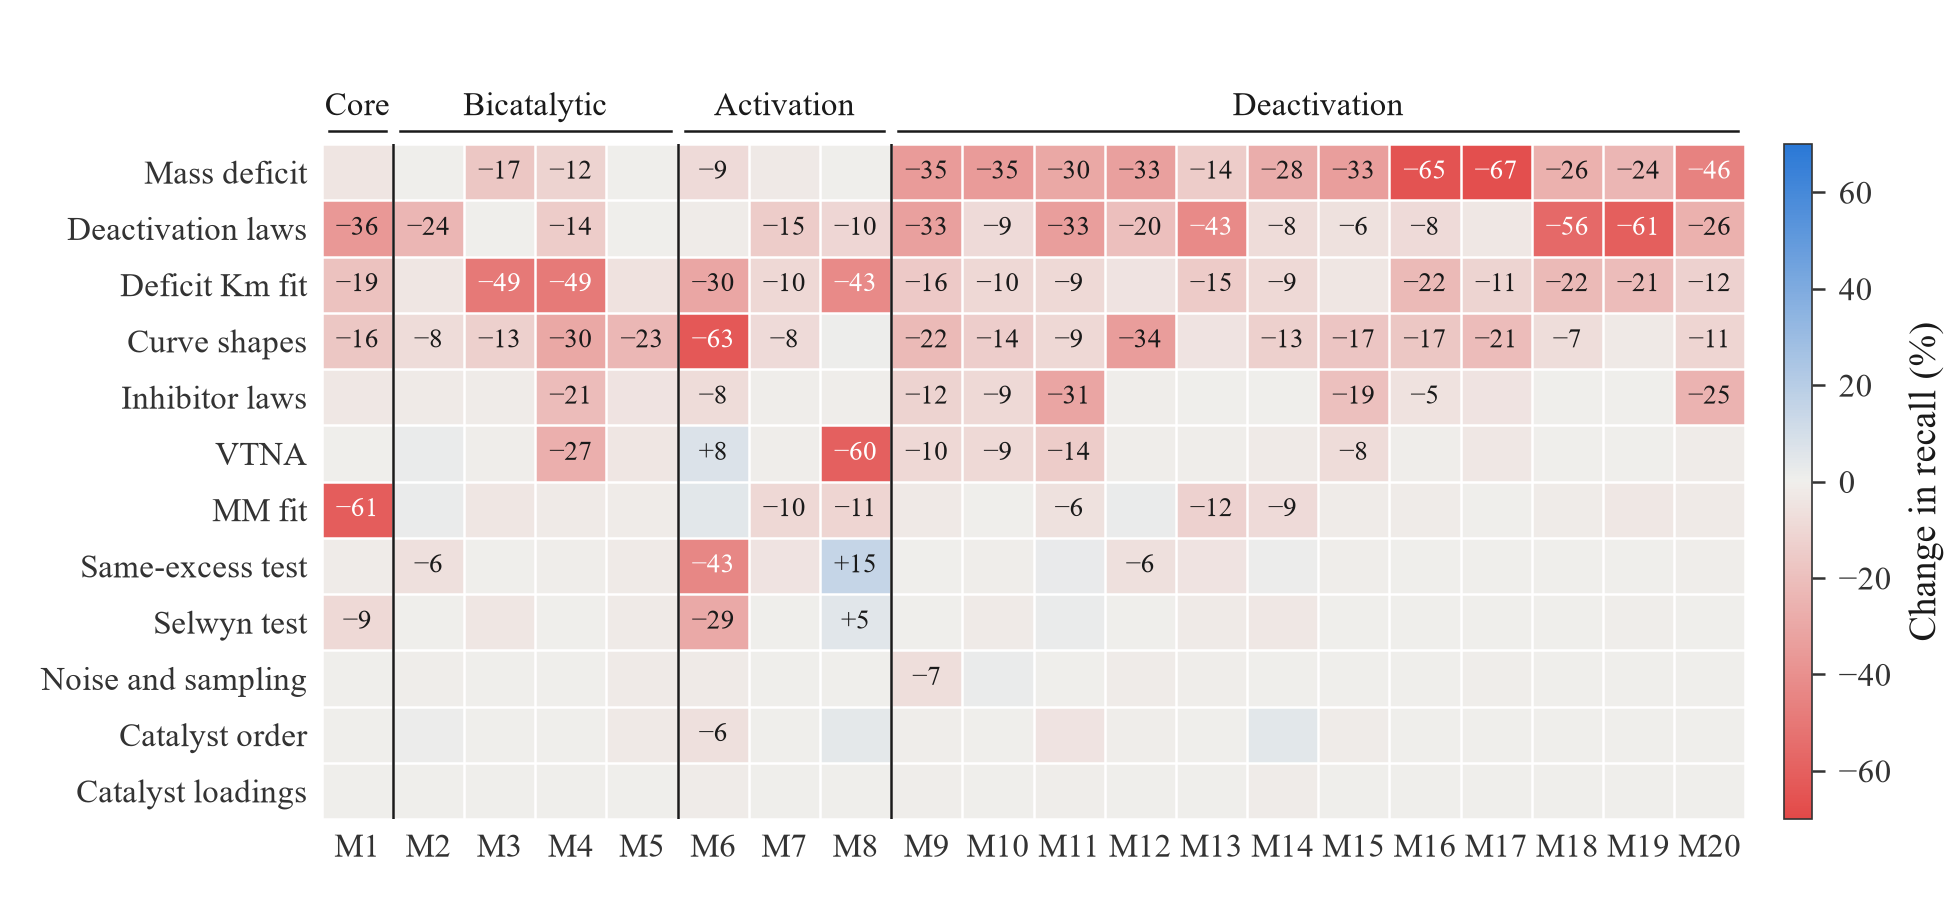

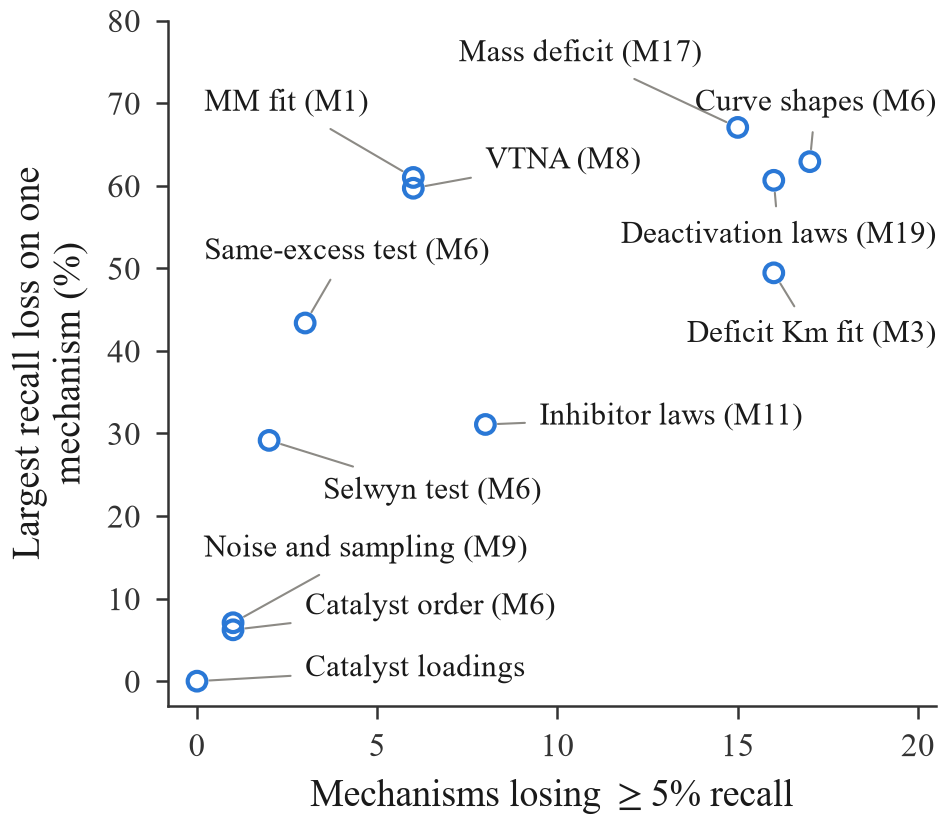

In [12]:
for f in ('family_accuracy_loss', 'family_recall_change', 'family_breadth'):
    display(Image(C.SUPPORTING / 'figures' / (f + '.png'), width=650))

The noise-and-sampling family permuted on the noisy test sets:

In [13]:
pd.read_csv(C.TABLES / 'permutation_noisy' / 'summary.csv').round(3)

,set,unit,n_columns,accuracy_before,accuracy_after,loss_points,loss_se,mechanisms_affected
0,test_6pts_1pct,Noise and sampling,5,81.788,81.409,0.379,0.030,0
1,test_6pts_5pct,Noise and sampling,5,49.554,49.280,0.274,0.024,0
